# Livrable 1 — Modélisation formelle
## Optimisation de tournées de livraison : du CVRP au CVRPTW

**Projet CesiCDP — Appel à manifestation d'intérêt ADEME**
Bloc *Algorithmique et optimisation combinatoire*

---

**Plan du notebook**

1. Contexte et enjeux
2. Du problème métier au problème algorithmique
3. Représentation formelle des données
4. Définition formelle des problèmes (CVRP, CVRPTW)
5. Étude de complexité
6. Modèle PLNE du CVRP
7. Extension PLNE au CVRPTW
8. Le trafic par tranche horaire : discussion de modélisation
9. Illustration : instance jouet, vérificateur de solution, taille du modèle
10. Synthèse et suite du projet
11. Références bibliographiques

## 1. Contexte et enjeux

Le transport routier de marchandises est l'un des premiers postes d'émission de gaz à effet de serre. Dans le cadre de son appel à manifestation d'intérêt sur les nouvelles solutions de mobilité, l'ADEME cherche des démonstrateurs capables de **réduire les kilomètres parcourus et le temps passé sur la route** par les véhicules de livraison.

CesiCDP a choisi d'attaquer ce sujet par la **gestion des tournées de livraison** : une entreprise dispose d'un dépôt, d'une flotte de camions et d'une liste de clients à livrer dans la journée. La question est simple à poser :

> *Dans quel ordre, et avec quel camion, faut-il visiter les clients pour que la durée totale des tournées soit la plus courte possible ?*

Chaque minute gagnée sur une tournée se traduit directement en carburant économisé, en émissions évitées et en coût d'exploitation réduit. C'est ce qui rend le problème intéressant pour l'ADEME : un gain de quelques pourcents, multiplié par des milliers de tournées quotidiennes, a un impact environnemental réel.

**Notre choix de périmètre.** Le sujet propose deux niveaux :

| Niveau | Problème | Contraintes |
|---|---|---|
| B (base) | **CVRP** | $k$ camions identiques de capacité $Q$ |
| A (avancé) | **CVRPTW** | CVRP + fenêtre de temps stricte par client, attente autorisée |

Nous visons le **niveau A**. La démarche suit un ordre naturel : on modélise d'abord le CVRP, qui est le cœur du problème, puis on l'enrichit avec les fenêtres de temps. Ainsi, le modèle de base reste disponible si le temps venait à manquer.

## 2. Du problème métier au problème algorithmique

Avant d'écrire la moindre équation, il faut traduire chaque élément du terrain en objet mathématique.

| Réalité terrain | Objet mathématique |
|---|---|
| Le dépôt et les clients | Les **sommets** d'un graphe |
| Le réseau routier entre deux lieux | Un **arc** pondéré par une durée de trajet |
| La quantité commandée par un client | Une **demande** $q_i$ |
| Le volume utile d'un camion | Une **capacité** $Q$ |
| Le nombre de camions disponibles | Un entier $K$ |
| Le créneau de livraison convenu | Une **fenêtre de temps** $[a_i, b_i]$ |
| Le temps de déchargement | Un **temps de service** $s_i$ |
| Une tournée de camion | Un **circuit** partant et revenant au dépôt |

**Hypothèses de travail** (à valider) :

- **H1 — Graphe complet.** On ne travaille pas sur le réseau routier brut mais sur le *graphe des plus courts chemins* entre lieux d'intérêt. Pour toute paire $(i, j)$, $t_{ij}$ est la durée du meilleur itinéraire routier de $i$ à $j$. Ce pré-calcul (Dijkstra sur le réseau réel) transforme un réseau de millions de tronçons en un graphe complet de $n+1$ sommets.
- **H2 — Inégalité triangulaire.** Grâce à H1, on a toujours $t_{ij} \le t_{ik} + t_{kj}$ : passer par un détour ne peut pas être plus court que le plus court chemin.
- **H3 — Demande non fractionnable.** Chaque client est livré par **un seul** camion, en **un seul** passage (pas de *split delivery*).
- **H4 — Flotte homogène.** Tous les camions ont la même capacité $Q$ et partent du même dépôt.
- **H5 — Faisabilité individuelle.** $q_i \le Q$ pour tout client, sinon l'instance est trivialement infaisable.
- **H6 — Temps statiques dans le modèle de base.** Les durées $t_{ij}$ sont fixes. L'effet du trafic par tranche horaire est traité comme une extension à la section 8.

> **Pourquoi H1 est importante.** Sans elle, un camion pourrait devoir traverser un même carrefour plusieurs fois, et le problème ne serait plus un problème de circuits sur des sommets clients. H1 nous ramène à la forme classique de la littérature.

## 3. Représentation formelle des données

Une **instance** du problème est un tuple

$$
\mathcal{I} = \big(G,\; t,\; q,\; Q,\; K,\; [a, b],\; s\big)
$$

avec :

- $G = (V, A)$ un **graphe orienté complet**, où $V = \{0, 1, \dots, n\}$.
  - Le sommet $0$ est le **dépôt**.
  - $V^{*} = V \setminus \{0\} = \{1, \dots, n\}$ est l'ensemble des **clients**.
  - $A = \{(i, j) \in V^2 : i \neq j\}$ est l'ensemble des arcs.
- $t_{ij} \ge 0$ la **durée de trajet** sur l'arc $(i, j)$. Dans le cas général $t_{ij} \neq t_{ji}$ (sens uniques, trafic asymétrique).
- $q_i \in \mathbb{N}$ la **demande** du client $i$, avec $q_0 = 0$.
- $Q \in \mathbb{N}$ la **capacité** commune des camions.
- $K \in \mathbb{N}^{*}$ le **nombre de camions** disponibles.
- *(CVRPTW)* $[a_i, b_i]$ la **fenêtre de temps** du sommet $i$ : le service doit **commencer** dans cet intervalle. Pour le dépôt, $[a_0, b_0]$ est l'horizon de travail (ouverture / fermeture du dépôt).
- *(CVRPTW)* $s_i \ge 0$ le **temps de service** au client $i$, avec $s_0 = 0$.

**Une solution** est un ensemble de $m \le K$ **routes** $\{R_1, \dots, R_m\}$, où chaque route est une séquence

$$
R_k = (0, v_1^k, v_2^k, \dots, v_{\ell_k}^k, 0)
$$

qui part du dépôt, visite des clients et revient au dépôt.

**Coût d'une route** : $\displaystyle c(R_k) = \sum_{p=0}^{\ell_k} t_{v_p^k\, v_{p+1}^k}$ (avec $v_0^k = v_{\ell_k+1}^k = 0$).

**Objectif** : minimiser $\displaystyle \sum_{k=1}^{m} c(R_k)$.

> **Note sur la fonction objectif.** Le sujet parle de minimiser la *durée totale*. Dans le CVRP, on minimise la somme des temps de trajet. Dans le CVRPTW, la durée réelle d'une tournée inclut aussi les temps de service (constants, donc sans effet sur l'optimisation) et les **temps d'attente**. Nous retenons la somme des temps de trajet comme objectif principal, car c'est le critère utilisé par les instances de référence (Solomon, VRPLIB) sur lesquelles nous devrons calculer notre gap. Une variante minimisant la durée totale (attente comprise) est donnée en section 7.

## 4. Définition formelle des problèmes

### 4.1 CVRP — Capacitated Vehicle Routing Problem

Une solution $\{R_1, \dots, R_m\}$ est **réalisable** pour le CVRP si :

1. **Couverture** : chaque client apparaît dans exactement une route,
   $\displaystyle \bigsqcup_{k=1}^{m} \{v_1^k, \dots, v_{\ell_k}^k\} = V^{*}$.
2. **Capacité** : la charge de chaque route ne dépasse pas la capacité,
   $\displaystyle \sum_{p=1}^{\ell_k} q_{v_p^k} \le Q \quad \forall k$.
3. **Flotte** : $m \le K$.

**Problème d'optimisation.** Trouver une solution réalisable de coût minimal.

**Version décisionnelle (CVRP-D).** Étant donné une instance et un entier $B$, existe-t-il une solution réalisable de coût $\le B$ ?

### 4.2 CVRPTW — CVRP with Time Windows

On ajoute à chaque route un **calendrier**. Notons $T_p$ l'heure de début de service au $p$-ième sommet de la route. Il se calcule de proche en proche :

$$
T_0 = a_0, \qquad T_{p+1} = \max\big(a_{v_{p+1}},\; T_p + s_{v_p} + t_{v_p v_{p+1}}\big)
$$

Le $\max$ traduit exactement la règle du sujet : **si le camion arrive avant l'ouverture, il attend**.

Une route est réalisable pour le CVRPTW si elle l'est pour le CVRP **et** si :

4. **Fenêtres de temps** : $T_p \le b_{v_p}$ pour tout sommet de la route, y compris le retour au dépôt (le camion doit être rentré avant la fermeture $b_0$).

Arriver après $b_i$ est **interdit** : c'est une fenêtre *dure* (hard time window), conformément au sujet.

### 4.3 Lien avec la littérature

Notre problème appartient à la grande famille des **Vehicle Routing Problems** introduite par Dantzig et Ramser (1959) sous le nom de *Truck Dispatching Problem*. On le situe ainsi :

```
          TSP  (1 véhicule, pas de capacité)
           │   + plusieurs véhicules + capacité
           ▼
          CVRP                                ← niveau B
           │   + fenêtres de temps
           ▼
          CVRPTW                              ← niveau A
           │   + temps de trajet dépendant de l'heure
           ▼
          TD-CVRPTW  (Time-Dependent)         ← extension (section 8)
```

Chaque flèche est une **généralisation** : le problème du dessous contient celui du dessus comme cas particulier. Cette observation est la clé de la preuve de complexité.

## 5. Étude de complexité

L'objectif de cette section est de montrer que **CVRP-D et CVRPTW-D sont NP-complets**, et donc que leurs versions d'optimisation sont **NP-difficiles**. Conséquence pratique : sauf si P = NP, aucun algorithme ne peut résoudre exactement des instances de plusieurs milliers de clients en temps raisonnable. C'est ce qui justifiera, dans les livrables suivants, le recours à une **métaheuristique**.

Rappel de la méthode : pour prouver qu'un problème $\Pi$ est NP-complet, il faut

1. montrer que $\Pi \in \text{NP}$ ;
2. trouver un problème $\Pi'$ **déjà connu** NP-complet et construire une **réduction polynomiale** $\Pi' \le_p \Pi$ : toute instance de $\Pi'$ se transforme en temps polynomial en une instance de $\Pi$ ayant la même réponse.

> **Attention au sens de la réduction.** On réduit le problème connu difficile **vers** notre problème. L'idée : « si je savais résoudre mon problème rapidement, je saurais résoudre un problème réputé difficile rapidement ». C'est l'erreur la plus fréquente dans ce type de preuve.

### 5.1 CVRP-D appartient à NP

**Certificat** : une liste de routes $\{R_1, \dots, R_m\}$.

**Vérification** en temps polynomial :
- vérifier que chaque client apparaît exactement une fois : $O(n)$ avec un tableau de marquage ;
- calculer la charge de chaque route et la comparer à $Q$ : $O(n)$ au total ;
- vérifier $m \le K$ : $O(1)$ ;
- calculer le coût total et le comparer à $B$ : $O(n)$.

La vérification est en $O(n)$ : CVRP-D $\in$ NP. Pour CVRPTW-D, il faut en plus calculer les heures $T_p$ par la récurrence de la section 4.2, ce qui reste en $O(n)$. Donc CVRPTW-D $\in$ NP.

### 5.2 Problème source : le TSP

Le problème du voyageur de commerce, en version décisionnelle :

> **TSP-D.** Étant donné un graphe complet de $n$ sommets, des coûts $c_{ij} \ge 0$ et un entier $B$, existe-t-il un cycle hamiltonien (passant une fois par chaque sommet) de coût $\le B$ ?

TSP-D est NP-complet. Cela découle de la NP-complétude du **cycle hamiltonien** (Karp, 1972) : étant donné un graphe $H$, on pose $c_{ij} = 1$ si $(i,j)$ est une arête de $H$, $c_{ij} = 2$ sinon, et $B = n$ ; $H$ a un cycle hamiltonien si et seulement si le TSP a un tour de coût $\le n$ (Garey et Johnson, 1979).

### 5.3 Réduction TSP-D $\le_p$ CVRP-D

**Construction.** Soit une instance de TSP-D : sommets $\{0, 1, \dots, n\}$, coûts $c_{ij}$, borne $B$. On construit l'instance de CVRP-D suivante :

| Élément CVRP | Valeur choisie |
|---|---|
| Dépôt | le sommet $0$ |
| Clients | les sommets $1, \dots, n$ |
| Durées | $t_{ij} = c_{ij}$ |
| Demandes | $q_i = 1$ pour tout client |
| Capacité | $Q = n$ |
| Flotte | $K = 1$ |
| Borne | $B$ (inchangée) |

La construction recopie les données : elle est en $O(n^2)$, donc **polynomiale**.

**Équivalence.**

- ($\Rightarrow$) Si le TSP admet un cycle hamiltonien de coût $\le B$, on le fait commencer en $0$ : c'est une route unique $(0, v_1, \dots, v_n, 0)$ qui visite tous les clients une fois. Sa charge vaut $n = Q$ (capacité respectée), elle utilise $1 \le K$ camion, et son coût est $\le B$. Le CVRP répond **oui**.
- ($\Leftarrow$) Si le CVRP admet une solution de coût $\le B$, comme $K = 1$ elle comporte une seule route, qui part de $0$, visite chaque client exactement une fois et revient en $0$. C'est un cycle hamiltonien de coût $\le B$. Le TSP répond **oui**.

Les deux instances ont toujours la même réponse : **TSP-D $\le_p$ CVRP-D**.

**Conclusion.** CVRP-D est dans NP et au moins aussi difficile qu'un problème NP-complet : **CVRP-D est NP-complet**, et le CVRP d'optimisation est **NP-difficile**.

### 5.4 Réduction CVRP-D $\le_p$ CVRPTW-D

On ajoute des fenêtres de temps qui ne contraignent rien :

- $a_i = 0$ et $s_i = 0$ pour tout sommet ;
- $b_i = M$ pour tout sommet, avec $M = \sum_{(i,j) \in A} t_{ij}$, valeur qui dépasse la durée de n'importe quelle route.

Toute route réalisable pour le CVRP respecte automatiquement ces fenêtres, et inversement. La construction est polynomiale et préserve la réponse : **CVRPTW-D est NP-complet**, et le CVRPTW d'optimisation est **NP-difficile**.

### 5.5 Un résultat plus fort pour les fenêtres de temps

Pour le CVRPTW, la difficulté ne porte pas seulement sur l'**optimisation** : **trouver simplement une solution réalisable** avec un nombre de camions fixé est déjà NP-complet (Savelsbergh, 1985).

Intuition : avec des fenêtres de temps, même un seul camion doit trouver un ordre de visite qui respecte tous les créneaux, ce qui revient à un TSP avec fenêtres de temps, dont la version réalisabilité est NP-complète.

De même, côté capacité seule : décider si les demandes tiennent dans $K$ camions de capacité $Q$ est exactement le problème du **bin packing**, lui aussi NP-complet. Le CVRP combine donc **deux sources de difficulté** : un problème d'**affectation** (bin packing : quel client dans quel camion) et un problème de **séquencement** (TSP : dans quel ordre).

**Conséquence pour la suite du projet.** Une métaheuristique pour le CVRPTW ne peut pas supposer qu'une solution réalisable est facile à obtenir. Il faudra soit une heuristique de construction robuste (par exemple l'insertion de Solomon, 1987), soit autoriser temporairement des solutions infaisables pénalisées dans la fonction objectif.

### 5.6 Ordre de grandeur de l'espace de recherche

Pour une seule route, le nombre d'ordres de visite de $n$ clients est $n!$. Le nombre de façons de découper ces clients en routes s'y ajoute. Quelques valeurs de $n!$ :

| $n$ | $n!$ |
|---|---|
| 10 | $3{,}6 \times 10^6$ |
| 20 | $2{,}4 \times 10^{18}$ |
| 50 | $3{,}0 \times 10^{64}$ |
| 1000 | $\approx 4 \times 10^{2567}$ |

Une énumération exhaustive est donc impossible bien avant d'atteindre les « plusieurs milliers de villes » du cahier des charges.

In [1]:
import math

# Ordre de grandeur de n! : nombre d'ordres de visite pour une seule route
for n in (10, 20, 50, 100, 1000, 5000):
    log10_fact = math.lgamma(n + 1) / math.log(10)
    print(f"n = {n:>5} clients  ->  n! ≈ 10^{log10_fact:,.1f}")

n =    10 clients  ->  n! ≈ 10^6.6
n =    20 clients  ->  n! ≈ 10^18.4
n =    50 clients  ->  n! ≈ 10^64.5
n =   100 clients  ->  n! ≈ 10^158.0
n =  1000 clients  ->  n! ≈ 10^2,567.6
n =  5000 clients  ->  n! ≈ 10^16,325.6


## 6. Modèle PLNE du CVRP

On propose une **formulation à deux indices** (on ne distingue pas les camions dans les variables). C'est un choix délibéré :

- les camions sont **identiques**, donc il est inutile de savoir *quel* camion fait *quelle* route ;
- une formulation à trois indices ($x_{ijk}$) multiplierait le nombre de variables par $K$ et créerait des **symétries** (permuter deux camions donne la même solution), qui ralentissent fortement les solveurs.

### 6.1 Variables de décision

| Variable | Domaine | Signification |
|---|---|---|
| $x_{ij}$ | $\{0, 1\}$ | vaut 1 si un camion emprunte l'arc $(i, j)$, 0 sinon, pour tout $(i, j) \in A$ |
| $u_i$ | $\mathbb{R}$ | **charge cumulée** du camion après avoir livré le client $i$, pour $i \in V^{*}$ |

Les variables $u_i$ sont continues : elles ne servent qu'à garantir la capacité et à éliminer les sous-tours.

### 6.2 Fonction objectif

$$
\min \; \sum_{(i,j) \in A} t_{ij}\, x_{ij} \tag{1}
$$

On minimise la durée totale de trajet, c'est-à-dire la somme des durées des arcs empruntés.

### 6.3 Contraintes

**Chaque client est visité exactement une fois** : un arc entrant et un arc sortant.

$$
\sum_{i \in V,\, i \neq j} x_{ij} = 1 \qquad \forall j \in V^{*} \tag{2}
$$

$$
\sum_{j \in V,\, j \neq i} x_{ij} = 1 \qquad \forall i \in V^{*} \tag{3}
$$

**Flotte limitée et conservation au dépôt** : au plus $K$ camions partent, et autant reviennent.

$$
\sum_{j \in V^{*}} x_{0j} \le K \tag{4}
$$

$$
\sum_{j \in V^{*}} x_{0j} = \sum_{i \in V^{*}} x_{i0} \tag{5}
$$

**Capacité et élimination des sous-tours** (formulation MTZ, Miller, Tucker et Zemlin, 1960, adaptée à la capacité) :

$$
u_j \ge u_i + q_j - Q\,(1 - x_{ij}) \qquad \forall i, j \in V^{*},\; i \neq j \tag{6}
$$

$$
q_i \le u_i \le Q \qquad \forall i \in V^{*} \tag{7}
$$

**Intégrité** :

$$
x_{ij} \in \{0, 1\} \qquad \forall (i, j) \in A \tag{8}
$$

### 6.4 Pourquoi ces contraintes suffisent : lecture de (6) et (7)

Les contraintes (2) et (3) seules ne garantissent pas des tournées partant du dépôt. Exemple : la solution « $1 \to 2 \to 3 \to 1$ » respecte (2) et (3) pour les clients 1, 2 et 3, mais forme un **sous-tour** déconnecté du dépôt, qu'aucun camion ne peut réaliser.

La contrainte (6) fonctionne comme un interrupteur :

- **si $x_{ij} = 1$** (le camion va de $i$ à $j$), elle devient $u_j \ge u_i + q_j$ : la charge cumulée augmente de la demande de $j$ ;
- **si $x_{ij} = 0$**, elle devient $u_j \ge u_i + q_j - Q$. Comme $u_i \le Q$ et $u_j \ge q_j$ d'après (7), le membre de droite est $\le q_j \le u_j$ : la contrainte est **toujours satisfaite**, donc **inactive**.

**Élimination des sous-tours.** Supposons un sous-tour $i_1 \to i_2 \to \dots \to i_r \to i_1$ ne passant pas par le dépôt. En sommant (6) le long du cycle :

$$
u_{i_1} \ge u_{i_1} + \sum_{p=1}^{r} q_{i_p}
$$

ce qui est impossible dès qu'une demande est strictement positive. Aucun sous-tour ne survit.

**Capacité.** Le long d'une route $0 \to v_1 \to \dots \to v_\ell \to 0$, la charge $u$ augmente au moins de la demande de chaque client visité, et (7) l'empêche de dépasser $Q$. La charge totale de la route est donc $\le Q$.

> Les contraintes (6) ne portent que sur les paires de **clients** : le dépôt joue le rôle de « point de remise à zéro » de la charge, ce qui permet aux routes de recommencer à charge nulle à chaque départ.

### 6.5 Taille du modèle et alternatives

| Élément | Nombre |
|---|---|
| Variables binaires $x_{ij}$ | $n(n+1)$ |
| Variables continues $u_i$ | $n$ |
| Contraintes (2)–(5) | $2n + 2$ |
| Contraintes MTZ (6) | $n(n-1)$ |

Le modèle est **compact** (nombre polynomial de contraintes), donc directement implémentable avec un solveur (PuLP + CBC, OR-Tools, Gurobi). Sa faiblesse est connue : sa **relaxation linéaire est faible**, ce qui limite la résolution exacte à quelques dizaines de clients.

L'alternative classique remplace (6)–(7) par les **contraintes de capacité arrondies** (*rounded capacity inequalities*, Laporte et Nobert, 1983) :

$$
\sum_{i \notin S}\; \sum_{j \in S} x_{ij} \;\ge\; \left\lceil \frac{\sum_{i \in S} q_i}{Q} \right\rceil \qquad \forall S \subseteq V^{*},\; S \neq \emptyset
$$

Elles signifient : « l'ensemble de clients $S$ doit recevoir au moins autant de camions que nécessaire pour transporter sa demande ». Elles sont beaucoup plus fortes, mais en nombre **exponentiel** ($2^n$) : il faut les ajouter dynamiquement (*branch-and-cut*). Nous gardons MTZ pour sa simplicité d'implémentation, en signalant cette piste pour le livrable final.

## 7. Extension PLNE au CVRPTW

On conserve **intégralement** le modèle (1)–(8) et on ajoute la dimension temporelle.

### 7.1 Variables supplémentaires

| Variable | Domaine | Signification |
|---|---|---|
| $T_i$ | $\mathbb{R}_{+}$ | **heure de début de service** au client $i$, pour $i \in V^{*}$ |

### 7.2 Contraintes supplémentaires

**Propagation du temps entre deux clients** :

$$
T_j \ge T_i + s_i + t_{ij} - M_{ij}\,(1 - x_{ij}) \qquad \forall i, j \in V^{*},\; i \neq j \tag{9}
$$

**Départ du dépôt** : le premier client d'une route ne peut être servi avant l'ouverture du dépôt plus le trajet.

$$
T_j \ge a_0 + t_{0j} \qquad \forall j \in V^{*} \text{ tels que } x_{0j} = 1 \tag{10}
$$

que l'on linéarise en $\;T_j \ge a_0 + t_{0j}\, x_{0j}\;$ (si $x_{0j} = 0$, la contrainte devient $T_j \ge a_0$, toujours vraie car $T_j \ge a_j \ge a_0$).

**Retour au dépôt avant sa fermeture** :

$$
T_i + s_i + t_{i0} \le b_0 + M_{i0}\,(1 - x_{i0}) \qquad \forall i \in V^{*} \tag{11}
$$

**Respect des fenêtres de temps** :

$$
a_i \le T_i \le b_i \qquad \forall i \in V^{*} \tag{12}
$$

### 7.3 Lecture des contraintes temporelles

**La contrainte (9) est le cœur du modèle.** Comme (6), c'est un interrupteur :

- si $x_{ij} = 1$, elle impose $T_j \ge T_i + s_i + t_{ij}$ : on ne peut pas commencer chez $j$ avant d'avoir fini chez $i$ et fait le trajet ;
- si $x_{ij} = 0$, le terme $-M_{ij}$ la rend inactive.

**L'attente est autorisée par construction.** La contrainte (9) est une inégalité « $\ge$ » et non une égalité. Si le camion arrive chez $j$ à $T_i + s_i + t_{ij} < a_j$, la contrainte (12) force $T_j \ge a_j$ : le modèle **choisit** de faire commencer le service plus tard, ce qui revient à attendre sur place. C'est exactement la règle du sujet, et c'est l'équivalent linéaire du $\max$ de la section 4.2.

**L'interdiction de livrer hors fenêtre** est portée par la borne supérieure $T_i \le b_i$ de (12) : une solution qui arriverait trop tard est simplement infaisable.

**Bonus : élimination des sous-tours.** Si tous les $s_i + t_{ij} > 0$, la contrainte (9) élimine à elle seule les sous-tours (même raisonnement par sommation qu'en 6.4). Les contraintes MTZ de capacité restent nécessaires pour la **capacité**.

### 7.4 Choix des constantes « big-M »

Prendre un $M$ énorme (par exemple $10^9$) est une mauvaise pratique : la relaxation linéaire devient très faible et le solveur rencontre des problèmes numériques. On prend la **plus petite valeur qui rende la contrainte inactive** quand $x_{ij} = 0$.

Pour (9), il faut $T_i + s_i + t_{ij} - M_{ij} \le T_j$ pour toutes valeurs admissibles. Le pire cas est $T_i = b_i$ et $T_j = a_j$ :

$$
M_{ij} = \max\big(0,\; b_i + s_i + t_{ij} - a_j\big)
$$

Pour (11), le pire cas est $T_i = b_i$ :

$$
M_{i0} = \max\big(0,\; b_i + s_i + t_{i0} - b_0\big)
$$

### 7.5 Prétraitement : élimination des arcs impossibles

Les fenêtres de temps permettent de **supprimer des arcs avant même de résoudre**. Si, même en partant au plus tôt de $i$, on arrive après la fermeture de $j$ :

$$
a_i + s_i + t_{ij} > b_j \quad \Longrightarrow \quad x_{ij} = 0
$$

De même pour la capacité : si $q_i + q_j > Q$, alors $x_{ij} = x_{ji} = 0$. Sur les instances de Solomon à fenêtres serrées, ce filtrage élimine une part importante des arcs, ce qui allège le modèle et guidera aussi la métaheuristique (listes de voisins candidats).

### 7.6 Variante d'objectif : la durée totale réelle

Si l'on veut minimiser la durée réelle de travail des chauffeurs (trajets + services + **attentes**), il faut connaître l'heure de départ et de retour de chaque route. On peut le faire sans quitter la formulation à deux indices en ajoutant deux variables par client :

- $R_i \ge 0$ : heure de retour au dépôt si $i$ est le **dernier** client d'une route, 0 sinon ;
- $D_j \ge 0$ : heure de départ du dépôt si $j$ est le **premier** client d'une route, 0 sinon.

$$
\begin{aligned}
& R_i \ge T_i + s_i + t_{i0} - M(1 - x_{i0}), \qquad R_i \le M\, x_{i0} && \forall i \in V^{*} \\
& D_j \le T_j - t_{0j} + M(1 - x_{0j}), \qquad D_j \le M\, x_{0j} && \forall j \in V^{*}
\end{aligned}
$$

$$
\min \; \sum_{i \in V^{*}} R_i - \sum_{j \in V^{*}} D_j
$$

La minimisation pousse $R_i$ vers le bas et $D_j$ vers le haut : à l'optimum, chaque camion part le plus tard possible et rentre le plus tôt possible, et l'objectif vaut la somme des durées réelles des tournées, attente comprise.

Nous retenons la **somme des temps de trajet** comme objectif officiel, car c'est celui des instances de référence (Solomon, Gehring et Homberger, VRPLIB) et donc celui qui permet de calculer le gap demandé. Ce choix est cohérent avec l'enjeu environnemental : les émissions sont liées au temps passé à rouler, pas au temps d'attente moteur coupé.

### 7.7 Modèle complet du CVRPTW (récapitulatif)

$$
\begin{aligned}
\min \quad & \sum_{(i,j) \in A} t_{ij}\, x_{ij} \\[4pt]
\text{s.c.} \quad
& \sum_{i \neq j} x_{ij} = 1, \quad \sum_{i \neq j} x_{ji} = 1 && \forall j \in V^{*} \\
& \sum_{j \in V^{*}} x_{0j} \le K, \quad \sum_{j \in V^{*}} x_{0j} = \sum_{i \in V^{*}} x_{i0} \\
& u_j \ge u_i + q_j - Q(1 - x_{ij}) && \forall i \ne j \in V^{*} \\
& q_i \le u_i \le Q && \forall i \in V^{*} \\
& T_j \ge T_i + s_i + t_{ij} - M_{ij}(1 - x_{ij}) && \forall i \ne j \in V^{*} \\
& T_j \ge a_0 + t_{0j}\, x_{0j} && \forall j \in V^{*} \\
& T_i + s_i + t_{i0} \le b_0 + M_{i0}(1 - x_{i0}) && \forall i \in V^{*} \\
& a_i \le T_i \le b_i && \forall i \in V^{*} \\
& x_{ij} \in \{0, 1\} && \forall (i,j) \in A
\end{aligned}
$$

## 8. Le trafic par tranche horaire : discussion de modélisation

Le sujet précise que l'optimisation *devra tenir compte du trafic prévu sur chaque axe pour les différentes tranches horaires*. Cela signifie que la durée d'un trajet dépend de l'**heure de départ** : traverser une ville à 8 h ne prend pas le même temps qu'à 14 h. Le problème devient un **Time-Dependent VRP** (TDVRP).

### 8.1 Modélisation des données

On découpe la journée en $H$ tranches horaires $[\tau_0, \tau_1[, [\tau_1, \tau_2[, \dots, [\tau_{H-1}, \tau_H[$. Pour chaque arc et chaque tranche, on connaît une **vitesse** $v_{ij}^h$ (ou un coefficient de congestion $\alpha_h$ appliqué à une vitesse de référence).

La durée de trajet devient une fonction de l'heure de départ $\theta$ :

$$
t_{ij}(\theta)
$$

### 8.2 Le piège à éviter : la propriété FIFO

La solution naïve « la durée de l'arc est celle de la tranche de départ » (**durées constantes par tranche**) a un défaut grave : elle peut violer la propriété **FIFO** (*First In, First Out*).

Exemple : un arc de 60 km. Départ à 8 h 59 en tranche de pointe (30 km/h) : arrivée à 10 h 59. Départ à 9 h 01 en tranche fluide (90 km/h) : arrivée à 9 h 41. **Partir plus tard fait arriver plus tôt** : un chauffeur aurait intérêt à attendre avant de partir, ce qui est irréaliste.

Ichoua, Gendreau et Potvin (2003) proposent la solution standard : ce sont les **vitesses** qui sont constantes par tranche, pas les durées. Quand un camion franchit le changement de tranche en cours de trajet, il **change de vitesse** pour la distance restante. La fonction $t_{ij}(\theta)$ obtenue est continue, linéaire par morceaux, et **respecte FIFO** :

$$
\theta_1 \le \theta_2 \implies \theta_1 + t_{ij}(\theta_1) \le \theta_2 + t_{ij}(\theta_2)
$$

### 8.3 Intégration au modèle et au projet

Intégrer $t_{ij}(\theta)$ dans un PLNE est possible (variables binaires par arc et par tranche, ou linéarisation par morceaux), mais le modèle grossit d'un facteur $H$ et devient inexploitable au-delà de quelques clients.

**Notre position, à valider avec le tuteur :**

1. Le **PLNE** est écrit avec des durées statiques $t_{ij}$ (sections 6 et 7). C'est le modèle de référence, compatible avec les instances VRPLIB et Solomon utilisées pour le calcul du gap.
2. La **métaheuristique** (livrables suivants) traitera le trafic sans difficulté supplémentaire de modélisation : l'évaluation d'une route se fait de proche en proche, en remplaçant simplement $t_{v_p v_{p+1}}$ par $t_{v_p v_{p+1}}(T_p + s_{v_p})$ dans la récurrence de la section 4.2. La propriété FIFO garantit que l'attente reste la bonne stratégie et que l'évaluation reste cohérente.
3. Le **plan d'expérience** pourra comparer les tournées optimisées avec et sans prise en compte du trafic, pour mesurer le gain apporté par la dépendance horaire.

**Complexité.** Le TDVRP généralise le CVRP (prendre une seule tranche, $H = 1$) : il est donc lui aussi NP-difficile, par la même réduction qu'en 5.3.

## 9. Illustration : instance jouet, vérificateur de solution, taille du modèle

Aucune implémentation n'est exigée à ce stade. Nous écrivons néanmoins trois petits outils qui **rendent la modélisation concrète** et serviront de base aux livrables suivants :

1. une structure de données pour représenter une instance ;
2. un **vérificateur de solution** qui applique exactement les définitions de la section 4 (c'est aussi l'algorithme polynomial de vérification de la preuve d'appartenance à NP, section 5.1) ;
3. un calcul de la **taille du PLNE** pour montrer pourquoi la résolution exacte ne passera pas à l'échelle.

### 9.1 Représentation d'une instance

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from dataclasses import dataclass


@dataclass
class Instance:
    # Instance de CVRPTW. Le sommet 0 est le dépôt.
    coords: np.ndarray   # (n+1, 2) coordonnées (pour l'affichage et le calcul des durées)
    demand: np.ndarray   # (n+1,)   q_i, avec q_0 = 0
    capacity: int        # Q
    n_vehicles: int      # K
    ready: np.ndarray    # (n+1,)   a_i  début de fenêtre
    due: np.ndarray      # (n+1,)   b_i  fin de fenêtre
    service: np.ndarray  # (n+1,)   s_i  temps de service

    def __post_init__(self):
        # Matrice des durées t_ij : distance euclidienne (comme dans les instances de Solomon)
        diff = self.coords[:, None, :] - self.coords[None, :, :]
        self.time = np.sqrt((diff ** 2).sum(axis=2))

    @property
    def n(self):
        return len(self.demand) - 1


def make_toy_instance(n=12, seed=7):
    # Petite instance aléatoire, avec des fenêtres de temps construites autour d'une route plausible.
    rng = np.random.default_rng(seed)
    coords = np.vstack([[50, 50], rng.uniform(0, 100, size=(n, 2))])
    demand = np.concatenate([[0], rng.integers(5, 20, size=n)])
    service = np.concatenate([[0], np.full(n, 10)])
    t0 = np.linalg.norm(coords - coords[0], axis=1)        # distance au dépôt
    centre = t0 + rng.uniform(20, 120, size=n + 1)          # centre de la fenêtre
    ready = np.maximum(0, centre - 40).round()
    due = (centre + 40).round()
    ready[0], due[0] = 0, 400                                # horizon du dépôt
    return Instance(coords, demand, capacity=60, n_vehicles=5,
                    ready=ready, due=due, service=service)


inst = make_toy_instance()
print(f"{inst.n} clients, K = {inst.n_vehicles} camions, Q = {inst.capacity}")
print(f"Demande totale = {inst.demand.sum()}  ->  au moins "
      f"{int(np.ceil(inst.demand.sum() / inst.capacity))} camions nécessaires (borne bin packing)")

12 clients, K = 5 camions, Q = 60
Demande totale = 154  ->  au moins 3 camions nécessaires (borne bin packing)


### 9.2 Vérificateur de solution

Cette fonction applique **à la lettre** les conditions de réalisabilité de la section 4. Elle calcule le calendrier avec la récurrence $T_{p+1} = \max(a_{v_{p+1}}, T_p + s_{v_p} + t_{v_p v_{p+1}})$, qui encode l'attente autorisée. Sa complexité est $O(n)$, ce qui illustre concrètement l'appartenance à NP.

In [3]:
def check_solution(inst, routes, verbose=True):
    # Vérifie une solution CVRPTW et renvoie (réalisable, coût, liste des violations).
    # routes : liste de listes de clients, sans le dépôt, ex. [[3, 1, 4], [2, 5]]
    violations = []

    # (1) Couverture : chaque client exactement une fois
    visited = [c for r in routes for c in r]
    missing = set(range(1, inst.n + 1)) - set(visited)
    duplicates = {c for c in visited if visited.count(c) > 1}
    if missing:
        violations.append(f"clients non visités : {sorted(missing)}")
    if duplicates:
        violations.append(f"clients visités plusieurs fois : {sorted(duplicates)}")

    # (3) Flotte
    if len(routes) > inst.n_vehicles:
        violations.append(f"{len(routes)} routes > K = {inst.n_vehicles}")

    total_travel, total_wait = 0.0, 0.0
    for k, route in enumerate(routes):
        # (2) Capacité
        load = inst.demand[route].sum()
        if load > inst.capacity:
            violations.append(f"route {k} : charge {load} > Q = {inst.capacity}")

        # (4) Fenêtres de temps, avec attente autorisée
        prev, T = 0, inst.ready[0]
        for c in route:
            arrival = T + inst.service[prev] + inst.time[prev, c]
            T = max(inst.ready[c], arrival)            # on attend si on arrive trop tôt
            total_wait += T - arrival
            if T > inst.due[c] + 1e-9:
                violations.append(f"route {k} : client {c} servi à {T:.1f} > b = {inst.due[c]:.0f}")
            total_travel += inst.time[prev, c]
            prev = c
        back = T + inst.service[prev] + inst.time[prev, 0]
        total_travel += inst.time[prev, 0]
        if back > inst.due[0] + 1e-9:
            violations.append(f"route {k} : retour dépôt à {back:.1f} > b0 = {inst.due[0]:.0f}")

    feasible = not violations
    if verbose:
        status = "RÉALISABLE" if feasible else "NON RÉALISABLE"
        print(f"{status} | temps de trajet = {total_travel:.1f} | attente = {total_wait:.1f}")
        for v in violations:
            print("  -", v)
    return feasible, total_travel, violations

### 9.3 Une solution construite simplement

Pour avoir quelque chose à vérifier, on construit une solution avec une règle très simple : on trie les clients par début de fenêtre et on ajoute chacun en fin de la route existante où il coûte le moins, si capacité et fenêtres le permettent ; sinon on ouvre une nouvelle route. **Ce n'est pas une méthode de résolution** (hors périmètre de ce livrable) : c'est juste un exemple pour exercer le vérificateur.

In [4]:
def naive_routes(inst):
    # Remplissage glouton par ordre de début de fenêtre (exemple pédagogique uniquement).
    order = sorted(range(1, inst.n + 1), key=lambda c: inst.ready[c])
    routes = []
    for c in order:
        # On ajoute c en fin de la route où cela coûte le moins, si c'est réalisable
        best, best_cost = None, float("inf")
        for k, r in enumerate(routes):
            ok, cost, _ = check_solution_route(inst, r + [c])
            if ok and cost < best_cost:
                best, best_cost = k, cost
        if best is None:
            routes.append([c])          # sinon on ouvre une nouvelle route
        else:
            routes[best].append(c)
    return routes


def check_solution_route(inst, route):
    # Teste une seule route (capacité + fenêtres) en réutilisant le vérificateur.
    sub = Instance(inst.coords, inst.demand, inst.capacity, 1,
                   inst.ready, inst.due, inst.service)
    _, cost, viol = check_solution(sub, [route], verbose=False)
    # On ignore les violations de couverture (on ne teste qu'une route)
    viol = [v for v in viol if "non visités" not in v]
    return not viol, cost, viol


routes = naive_routes(inst)
print("Routes :", routes)
check_solution(inst, routes)

print("\nOn casse volontairement la solution (un client en double, un client oublié) :")
broken = [r[:] for r in routes]
broken[0].append(broken[1][0])
broken[-1] = broken[-1][:-1]
_ = check_solution(inst, broken)

Routes : [[7, 2, 8], [5, 3, 4], [1, 6], [9, 10], [12, 11]]
RÉALISABLE | temps de trajet = 736.4 | attente = 35.5

On casse volontairement la solution (un client en double, un client oublié) :
NON RÉALISABLE | temps de trajet = 752.7 | attente = 35.5
  - clients non visités : [11]
  - clients visités plusieurs fois : [5]
  - route 0 : client 5 servi à 184.7 > b = 110


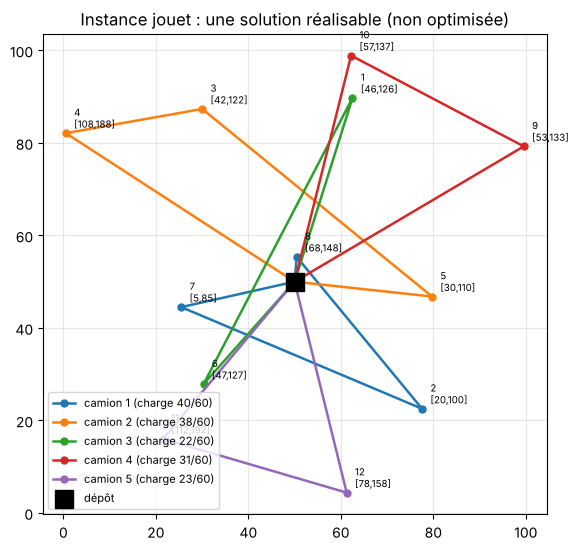

In [5]:
def plot_solution(inst, routes, title=""):
    fig, ax = plt.subplots(figsize=(6.5, 6.5))
    colors = plt.cm.tab10.colors
    for k, route in enumerate(routes):
        path = [0] + route + [0]
        xy = inst.coords[path]
        ax.plot(xy[:, 0], xy[:, 1], "-o", color=colors[k % 10], lw=1.8, ms=5,
                label=f"camion {k + 1} (charge {inst.demand[route].sum()}/{inst.capacity})")
    ax.scatter(*inst.coords[0], marker="s", s=160, c="black", zorder=5, label="dépôt")
    for c in range(1, inst.n + 1):
        ax.annotate(f"{c}\n[{inst.ready[c]:.0f},{inst.due[c]:.0f}]", inst.coords[c],
                    textcoords="offset points", xytext=(6, 4), fontsize=7)
    ax.set_title(title)
    ax.set_aspect("equal")
    ax.legend(fontsize=8, loc="lower left")
    ax.grid(alpha=0.3)
    plt.show()


plot_solution(inst, routes, "Instance jouet : une solution réalisable (non optimisée)")

### 9.4 Taille du PLNE en fonction du nombre de clients

On applique les formules des sections 6.5 et 7.2 pour estimer la taille du modèle CVRPTW.

In [6]:
def plne_size(n):
    # Nombre de variables et de contraintes du modèle CVRPTW des sections 6 et 7.
    x_vars = n * (n + 1)                 # x_ij
    cont_vars = 2 * n                    # u_i et T_i
    cons = (2 * n + 2)                   # (2)-(5)
    cons += 2 * n * (n - 1)              # MTZ capacité (6) + propagation du temps (9)
    cons += 2 * n                        # (10) et (11)
    return x_vars, cont_vars, cons


print(f"{'n clients':>10} | {'binaires':>14} | {'continues':>10} | {'contraintes':>14}")
print("-" * 58)
for n in (10, 25, 50, 100, 1000, 5000):
    xb, xc, c = plne_size(n)
    print(f"{n:>10} | {xb:>14,} | {xc:>10,} | {c:>14,}")

 n clients |       binaires |  continues |    contraintes
----------------------------------------------------------
        10 |            110 |         20 |            222
        25 |            650 |         50 |          1,302
        50 |          2,550 |        100 |          5,102
       100 |         10,100 |        200 |         20,202
      1000 |      1,001,000 |      2,000 |      2,002,002
      5000 |     25,005,000 |     10,000 |     50,010,002


**Lecture.** Le nombre de variables et de contraintes croît en $O(n^2)$ : c'est **polynomial**, donc le modèle s'écrit sans problème même pour 5 000 clients (environ 25 millions de variables binaires). Ce n'est pas la *taille* du modèle qui pose problème, c'est le **temps de résolution**, qui croît de façon exponentielle à cause de la NP-difficulté démontrée en section 5. En pratique, un solveur exact avec la formulation MTZ prouve l'optimalité jusqu'à quelques dizaines de clients.

Le PLNE gardera néanmoins trois usages dans la suite du projet :
- **validation** de la métaheuristique sur de petites instances, où l'on peut obtenir l'optimum exact ;
- **borne inférieure** via la relaxation linéaire, pour encadrer la qualité de nos solutions ;
- **documentation** précise et non ambiguë du problème traité.

## 10. Synthèse et suite du projet

**Ce que nous avons établi :**

| Élément | Résultat |
|---|---|
| Problème traité | CVRPTW (niveau A), construit sur le CVRP (niveau B) |
| Données | graphe complet orienté, demandes, capacité, flotte, fenêtres, temps de service |
| Objectif | minimiser la somme des temps de trajet |
| Complexité | CVRP et CVRPTW NP-difficiles (réductions TSP → CVRP → CVRPTW) ; la simple réalisabilité du CVRPTW à flotte fixée est NP-complète |
| Modèle PLNE | formulation à 2 indices, MTZ pour capacité et sous-tours, contraintes de temps avec big-M ajustés |
| Trafic | durées dépendantes de l'heure selon Ichoua et al. (2003), propriété FIFO, intégré dans l'évaluation de la métaheuristique |

**Points à valider avec le tuteur :**

1. Hypothèse H1 (graphe complet des plus courts chemins) et H6 (temps statiques dans le PLNE).
2. Choix de l'objectif : temps de trajet seul plutôt que durée totale avec attente.
3. Traitement du trafic par la métaheuristique plutôt que dans le PLNE.

**Prochaines étapes :**

- **Conception algorithmique** : choix de la métaheuristique (pistes : ALNS, recherche tabou, algorithme génétique hybride type HGS), définition des voisinages (2-opt, relocate, swap, 2-opt*) et heuristique de construction (insertion de Solomon).
- **Implémentation** en Python optimisé (NumPy, éventuellement Numba) pour tenir plusieurs milliers de clients.
- **Étude expérimentale** sur au moins 20 instances (Solomon pour le CVRPTW, VRPLIB pour le CVRP) avec calcul du gap par rapport aux meilleures solutions connues.

## 11. Références bibliographiques

1. **Dantzig, G. B., & Ramser, J. H.** (1959). The truck dispatching problem. *Management Science*, 6(1), 80–91. — Article fondateur du VRP.
2. **Toth, P., & Vigo, D.** (Eds.) (2014). *Vehicle Routing: Problems, Methods, and Applications* (2nd ed.). SIAM. — Ouvrage de référence sur toutes les variantes du VRP.
3. **Miller, C. E., Tucker, A. W., & Zemlin, R. A.** (1960). Integer programming formulation of traveling salesman problems. *Journal of the ACM*, 7(4), 326–329. — Contraintes MTZ d'élimination des sous-tours.
4. **Karp, R. M.** (1972). Reducibility among combinatorial problems. In *Complexity of Computer Computations* (pp. 85–103). Springer. — NP-complétude du cycle hamiltonien.
5. **Garey, M. R., & Johnson, D. S.** (1979). *Computers and Intractability: A Guide to the Theory of NP-Completeness*. W. H. Freeman. — Référence sur les réductions et la NP-complétude (TSP, bin packing).
6. **Lenstra, J. K., & Rinnooy Kan, A. H. G.** (1981). Complexity of vehicle routing and scheduling problems. *Networks*, 11(2), 221–227. — Complexité des problèmes de tournées.
7. **Laporte, G., & Nobert, Y.** (1983). A branch and bound algorithm for the capacitated vehicle routing problem. *Operations-Research-Spektrum*, 5(2), 77–85. — Contraintes de capacité arrondies.
8. **Savelsbergh, M. W. P.** (1985). Local search in routing problems with time windows. *Annals of Operations Research*, 4(1), 285–305. — NP-complétude de la réalisabilité avec fenêtres de temps.
9. **Solomon, M. M.** (1987). Algorithms for the vehicle routing and scheduling problems with time window constraints. *Operations Research*, 35(2), 254–265. — Instances de référence du VRPTW et heuristiques d'insertion.
10. **Desrochers, M., Desrosiers, J., & Solomon, M.** (1992). A new optimization algorithm for the vehicle routing problem with time windows. *Operations Research*, 40(2), 342–354. — Formulation et résolution exacte du VRPTW.
11. **Ichoua, S., Gendreau, M., & Potvin, J.-Y.** (2003). Vehicle dispatching with time-dependent travel times. *European Journal of Operational Research*, 144(2), 379–396. — Modèle de trafic par tranches respectant FIFO.
12. **Uchoa, E., Pecin, D., Pessoa, A., Poggi, M., Vidal, T., & Subramanian, A.** (2017). New benchmark instances for the capacitated vehicle routing problem. *European Journal of Operational Research*, 257(3), 845–858. — Instances X de la VRPLIB.

Validation : Pas de doublon; verif time window; verif tte les villes parcouru
